# Experiment 5: Polynomial Regression on California Housing Dataset

**Aim:** To implement Polynomial Regression using Python on the California Housing Dataset and study the difference between Linear Regression and Polynomial Regression for predicting housing prices.

**Dataset:** California Housing dataset (`sklearn.datasets.fetch_california_housing`). Feature used: Median Income (`MedInc`); target: Median House Value.

In [1]:
# Polynomial Regression on California Housing Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Load dataset
housing = fetch_california_housing()

# Create DataFrame
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# Target Variable
df['HouseValue'] = housing.target

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  HouseValue  
0    -122.23       4.526  
1    -122.22       3.585  
2    -122.24       3.521  
3    -122.25       3.413  
4    -122.25       3.422  


In [3]:
# Independent and dependent variables
X = df[['MedInc']]
y = df['HouseValue']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 16512
Testing samples : 4128


In [4]:
# Polynomial Feature Transformation
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Model Training
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Prediction
y_pred = model.predict(X_test_poly)

print("Polynomial terms:", list(poly.get_feature_names_out()))
print("Coefficients    :", model.coef_)
print("Intercept       :", model.intercept_)

Polynomial terms: ['1', 'MedInc', 'MedInc^2']
Coefficients    : [ 0.          0.53359111 -0.010508  ]
Intercept       : 0.19756732564563295


In [5]:
# Performance Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error :", mse)
print("Root Mean Squared Error :", rmse)
print("R2 Score :", r2)

Mean Squared Error : 0.7032732680932144
Root Mean Squared Error : 0.8386138969115731
R2 Score : 0.46331772769346224


In [6]:
# Simple Linear Regression on the same feature, for comparison
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression     -> MSE:", mean_squared_error(y_test, y_pred_linear),
      " R2:", r2_score(y_test, y_pred_linear))
print("Polynomial Regression -> MSE:", mse, " R2:", r2)

Linear Regression     -> MSE: 0.7091157771765548  R2: 0.45885918903846656
Polynomial Regression -> MSE: 0.7032732680932144  R2: 0.46331772769346224


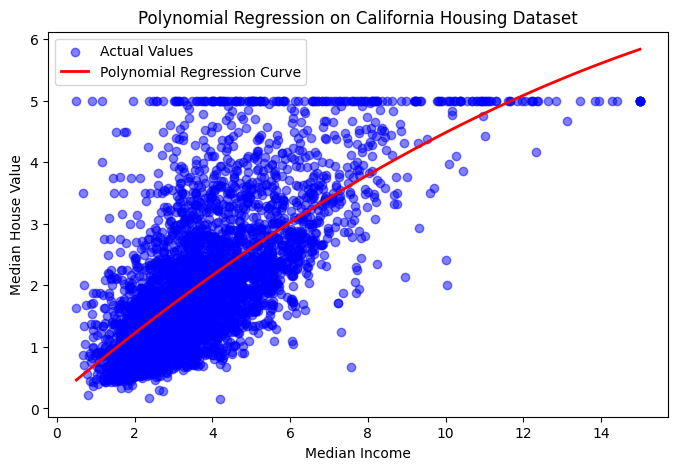

In [7]:
# Visualization
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Actual Values')

sorted_indices = np.argsort(X_test.values.flatten())

plt.plot(
    X_test.values.flatten()[sorted_indices],
    y_pred[sorted_indices],
    color='red', linewidth=2, label='Polynomial Regression Curve'
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Polynomial Regression on California Housing Dataset")
plt.legend()
plt.savefig("output/Exp5_polynomial_regression.png", dpi=150, bbox_inches="tight")
plt.show()

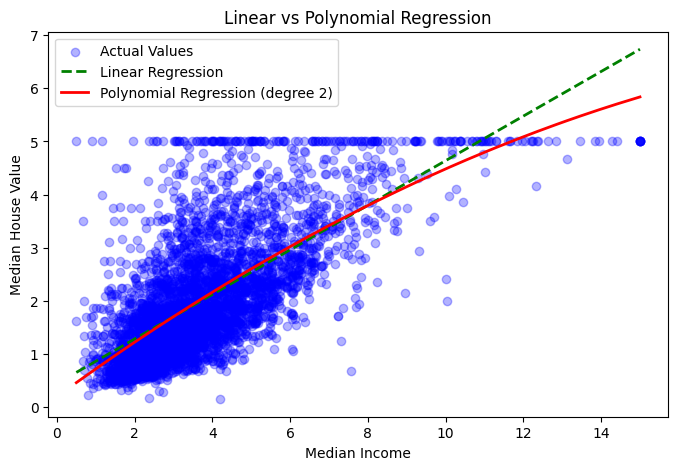

In [8]:
# Linear vs Polynomial fit
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', alpha=0.3, label='Actual Values')
plt.plot(X_test.values.flatten()[sorted_indices], y_pred_linear[sorted_indices],
         color='green', linewidth=2, linestyle='--', label='Linear Regression')
plt.plot(X_test.values.flatten()[sorted_indices], y_pred[sorted_indices],
         color='red', linewidth=2, label='Polynomial Regression (degree 2)')
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.savefig("output/Exp5_linear_vs_polynomial.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
Polynomial Regression was successfully implemented on the California Housing Dataset. A degree-2 polynomial of Median Income was fitted to House Value and evaluated using MSE, RMSE and R2 Score, and compared against simple linear regression on the same feature.